# Soal 23 — PSO-CNN untuk Hyperparameter Human Activity Recognition

**Nama:** Marsa Naufal  **NIM:** 04231047  **Seed:** 47 (dua digit terakhir NIM)
**Dataset:** D9 — Human Activity Recognition Using Smartphones, UCI (30 relawan, smartphone di pinggang, sensor 50 Hz)
**Library:** `pyswarms` (PSO), `PyTorch` (1D-CNN), `scikit-learn` (split dan metrik).

Task-nya sama dengan Soal 17: klasifikasi 6 aktivitas dari **sinyal inertial mentah** (window 128 sampel = 2.56 detik) dengan 1D-CNN dan pembagian subjek train/test bawaan dataset. Bedanya, di sini hyperparameter CNN **dicari otomatis oleh PSO**.

Alur: *Business Understanding → Data Understanding → Data Preparation → Modeling → Evaluation → Interpretasi Hasil*. Jawaban butir (a)–(d) ditandai **Jawaban 23a–23d**.

## 1. Business Understanding

**Latar belakang.** Pengenalan aktivitas dari sensor HP dipakai untuk aplikasi kesehatan (menghitung waktu aktif), pemantauan lansia (deteksi berbaring terlalu lama), dan kebugaran. 1D-CNN cocok untuk sinyal sensor, tetapi performanya bergantung pada **hyperparameter**: jumlah filter, ukuran kernel, dropout, ukuran dense, dan learning rate. Mencoba semua kombinasi satu per satu (*grid search*) sangat mahal. PSO menawarkan pencarian yang lebih hemat: sekelompok "penjelajah" saling berbagi info konfigurasi terbaik. Ibaratnya mencari warung terenak di kota bersama teman-teman lewat grup chat, bukan mendatangi semua warung satu per satu.

**Rumusan masalah.**
1. Bagaimana merepresentasikan hyperparameter CNN (sebagian diskret, sebagian kontinu) sebagai posisi partikel PSO?
2. Dengan anggaran komputasi terbatas, apakah PSO menemukan konfigurasi CNN yang lebih baik dari konfigurasi manual?
3. Apakah peningkatan performanya sebanding dengan biaya tuning?

**Tujuan.** Menjalankan PSO dengan fitness $1 - \text{macro-F1}_{val}$ + penalti jumlah parameter, melaporkan konfigurasi terbaik, lalu membandingkannya dengan CNN manual di test set (subjek yang tidak pernah dilihat).

**Kriteria kesuksesan.**

| Kriteria | Ambang |
|---|---|
| Accuracy dan macro-F1 test CNN hasil PSO | ≥ 0.88 |
| PSO vs baseline manual | macro-F1 test rata-rata (3 seed) ≥ baseline |
| Anggaran tuning | ≤ 30 evaluasi kandidat, ≤ 25 menit di CPU laptop |

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import time, copy, os
from pyswarms.single.global_best import GlobalBestPSO
from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, classification_report
import logging
logging.getLogger("pyswarms").setLevel(logging.WARNING)

SEED = 47
np.random.seed(SEED); torch.manual_seed(SEED)
torch.set_num_threads(os.cpu_count())
pd.set_option("display.width", 160)
plt.rcParams["figure.dpi"] = 110
print("CPU threads:", torch.get_num_threads())

CPU threads: 8


## 2. Data Understanding

### 2.1 Memuat sinyal inertial mentah
Dipakai **6 channel**: *body acceleration* x/y/z (percepatan tubuh setelah gravitasi dibuang) dan *body gyroscope* x/y/z (kecepatan sudut). Setiap baris file = satu window 128 sampel.

In [2]:
ROOT = "data/human+activity+recognition+using+smartphones"
CHANNELS = ["body_acc_x", "body_acc_y", "body_acc_z", "body_gyro_x", "body_gyro_y", "body_gyro_z"]
ACT = {1: "WALKING", 2: "WALKING_UPSTAIRS", 3: "WALKING_DOWNSTAIRS", 4: "SITTING", 5: "STANDING", 6: "LAYING"}
ACT_NAMES = [ACT[i] for i in range(1, 7)]

def load(split):
    X = np.stack([np.loadtxt(f"{ROOT}/{split}/Inertial Signals/{c}_{split}.txt") for c in CHANNELS], axis=1)
    y = np.loadtxt(f"{ROOT}/{split}/y_{split}.txt", dtype=int) - 1          # label 0..5
    subj = np.loadtxt(f"{ROOT}/{split}/subject_{split}.txt", dtype=int)
    return X.astype(np.float32), y, subj

X_train_full, y_train_full, s_train_full = load("train")
X_test, y_test, s_test = load("test")
print("Train:", X_train_full.shape, "| Test:", X_test.shape, "  (window, channel, waktu)")
print("Subjek train:", sorted(set(s_train_full)), "\nSubjek test :", sorted(set(s_test)))

Train: (7352, 6, 128) | Test: (2947, 6, 128)   (window, channel, waktu)
Subjek train: [np.int64(1), np.int64(3), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(11), np.int64(14), np.int64(15), np.int64(16), np.int64(17), np.int64(19), np.int64(21), np.int64(22), np.int64(23), np.int64(25), np.int64(26), np.int64(27), np.int64(28), np.int64(29), np.int64(30)] 
Subjek test : [np.int64(2), np.int64(4), np.int64(9), np.int64(10), np.int64(12), np.int64(13), np.int64(18), np.int64(20), np.int64(24)]


In [3]:
# Sampel: 20 window pertama, diringkas per channel (mean & std) karena tiap window berisi 6×128 angka
sampel = pd.DataFrame({"subjek": s_train_full[:20], "aktivitas": [ACT_NAMES[i] for i in y_train_full[:20]]})
for k, c in enumerate(CHANNELS):
    sampel[f"{c}_mean"] = X_train_full[:20, k].mean(1).round(4)
    sampel[f"{c}_std"] = X_train_full[:20, k].std(1).round(4)
sampel

,subjek,aktivitas,body_acc_x_mean,body_acc_x_std,body_acc_y_mean,body_acc_y_std,body_acc_z_mean,body_acc_z_std,body_gyro_x_mean,body_gyro_x_std,body_gyro_y_mean,body_gyro_y_std,body_gyro_z_mean,body_gyro_z_std
0,1,STANDING,0.0023,0.0029,-0.0017,0.0046,-0.0081,0.0185,0.0223,0.0144,0.0194,0.0198,0.0095,0.0059
1,1,STANDING,0.0002,0.0020,0.0004,0.0059,-0.0050,0.0101,0.0119,0.0163,-0.0043,0.0104,0.0063,0.0074
2,1,STANDING,0.0004,0.0029,-0.0012,0.0073,-0.0017,0.0068,-0.0041,0.0223,-0.0126,0.0069,0.0043,0.0088
3,1,STANDING,0.0003,0.0027,-0.0048,0.0046,-0.0049,0.0047,-0.0162,0.0092,-0.0077,0.0078,-0.0004,0.0082
4,1,STANDING,-0.0002,0.0020,0.0003,0.0050,-0.0023,0.0047,-0.0065,0.0145,-0.0002,0.0078,-0.0040,0.0083
5,1,STANDING,-0.0001,0.0023,0.0037,0.0033,0.0010,0.0038,-0.0011,0.0145,0.0018,0.0080,-0.0032,0.0103
6,1,STANDING,0.0004,0.0024,-0.0013,0.0073,-0.0006,0.0060,-0.0010,0.0119,-0.0039,0.0102,0.0040,0.0122
7,1,STANDING,-0.0000,0.0025,-0.0070,0.0074,-0.0056,0.0063,0.0036,0.0111,-0.0016,0.0116,0.0034,0.0125
8,1,STANDING,-0.0001,0.0023,-0.0024,0.0083,-0.0041,0.0059,0.0029,0.0096,0.0036,0.0074,-0.0037,0.0083
9,1,STANDING,0.0006,0.0031,0.0038,0.0064,0.0007,0.0055,0.0044,0.0148,0.0015,0.0117,-0.0033,0.0114


### 2.2 Atribut, statistik, missing value, duplikasi, outlier

| Komponen | Isi |
|---|---|
| Input per window | 6 channel × 128 titik waktu, float (acc dalam satuan g, gyro dalam rad/s) |
| Label | 6 aktivitas (integer 1–6, diubah menjadi 0–5) |
| Subjek | ID relawan 1–30; 21 orang di train, 9 orang di test (bawaan dataset) |
| Window | 2.56 detik dengan overlap 50% antar-window |

In [4]:
stat = pd.DataFrame({c: {"mean": X_train_full[:, k].mean(), "std": X_train_full[:, k].std(),
                         "min": X_train_full[:, k].min(), "max": X_train_full[:, k].max(),
                         "p99.9 |x|": np.percentile(np.abs(X_train_full[:, k]), 99.9)}
                     for k, c in enumerate(CHANNELS)}).T
display(stat.round(4))
print("NaN di train/test:", np.isnan(X_train_full).sum(), np.isnan(X_test).sum())
print("Window duplikat persis di train:", len(X_train_full) - len(np.unique(X_train_full.reshape(len(X_train_full), -1), axis=0)))
z = np.abs((X_train_full - X_train_full.mean((0, 2), keepdims=True)) / X_train_full.std((0, 2), keepdims=True))
print(f"Porsi titik dengan |z| > 5 (lonjakan ekstrem): {(z > 5).mean()*100:.3f}%")

,mean,std,min,max,p99.9 |x|
body_acc_x,-0.0006,0.1948,-1.2322,1.2999,0.9749
body_acc_y,-0.0003,0.1224,-1.3453,0.9760,0.6960
body_acc_z,-0.0003,0.1069,-1.3647,1.0669,0.6380
body_gyro_x,0.0005,0.4068,-4.7337,4.1555,2.2618
body_gyro_y,-0.0008,0.3819,-5.9743,5.7461,2.5143
body_gyro_z,0.0001,0.2557,-2.7630,2.3660,1.4283


NaN di train/test: 0 0
Window duplikat persis di train: 0


Porsi titik dengan |z| > 5 (lonjakan ekstrem): 0.210%


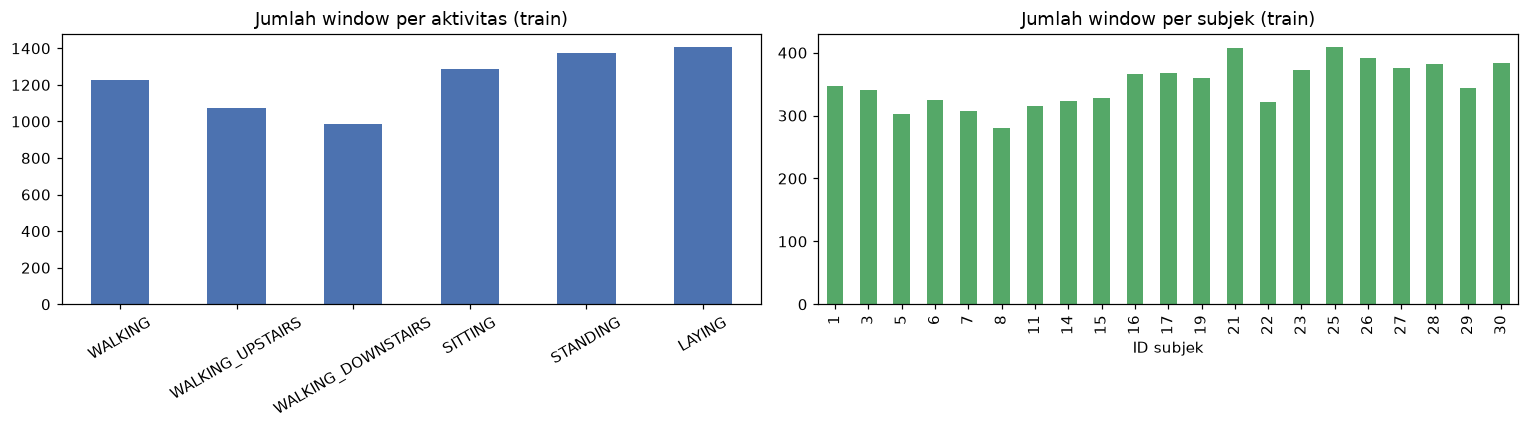

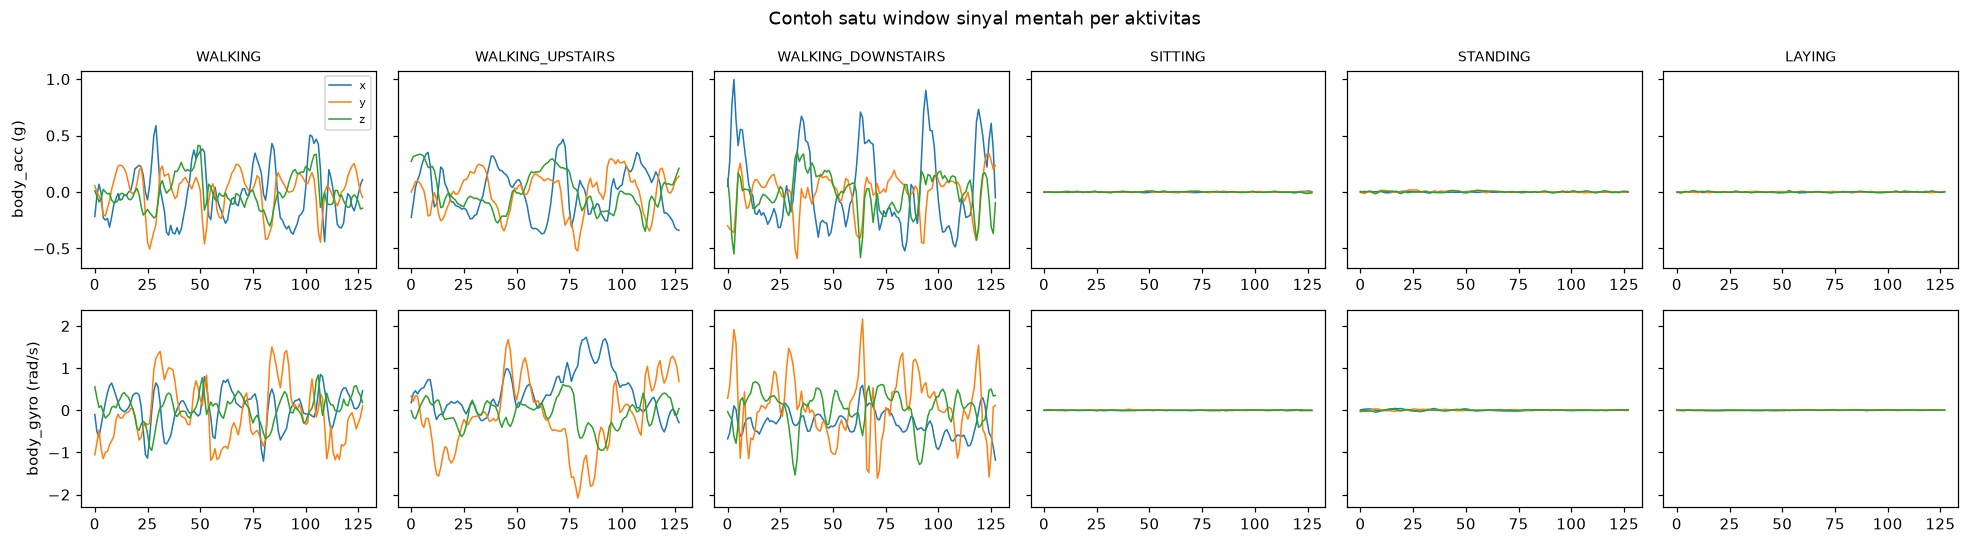

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
pd.Series(y_train_full).map(dict(enumerate(ACT_NAMES))).value_counts().reindex(ACT_NAMES).plot.bar(ax=axes[0], color="#4C72B0")
axes[0].set_title("Jumlah window per aktivitas (train)"); axes[0].tick_params(axis="x", rotation=30)
pd.Series(s_train_full).value_counts().sort_index().plot.bar(ax=axes[1], color="#55A868")
axes[1].set_title("Jumlah window per subjek (train)"); axes[1].set_xlabel("ID subjek")
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(2, 6, figsize=(18, 5), sharey="row")
for j in range(6):
    i = np.where(y_train_full == j)[0][10]
    for k in range(3):
        axes[0, j].plot(X_train_full[i, k], lw=1, label="xyz"[k]); axes[1, j].plot(X_train_full[i, 3 + k], lw=1, label="xyz"[k])
    axes[0, j].set_title(ACT_NAMES[j], fontsize=9)
axes[0, 0].set_ylabel("body_acc (g)"); axes[1, 0].set_ylabel("body_gyro (rad/s)"); axes[0, 0].legend(fontsize=7)
plt.suptitle("Contoh satu window sinyal mentah per aktivitas"); plt.tight_layout(); plt.show()

**Interpretasi Data Understanding.**
- Train berisi **7.352 window dari 21 subjek**, test berisi **2.947 window dari 9 subjek lain**. Setiap window berbentuk 6 channel × 128 titik.
- **Tidak ada NaN dan tidak ada window duplikat.** Rata-rata tiap channel ≈ 0, karena gravitasi sudah dibuang dari *body_acc*. Skala gyro (std 0.26–0.41 rad/s) lebih besar dari acc (std 0.11–0.19 g), jadi normalisasi per channel diperlukan.
- Lonjakan ekstrem (|z| > 5) hanya **0.21%** titik, dan wajar terjadi saat kaki menghentak, jadi tidak dibuang.
- Kelas **cukup seimbang** (986–1.407 window per aktivitas). WALKING_DOWNSTAIRS paling sedikit, dan inilah alasan memakai macro-F1.
- **Contoh sinyal:**
  - Aktivitas dinamis (WALKING, UPSTAIRS, DOWNSTAIRS) menghasilkan gelombang periodik yang besar.
  - Aktivitas statis (SITTING, STANDING, LAYING) hampir datar.
  - Tanpa komponen gravitasi, tiga aktivitas statis ini **mirip satu sama lain**. Ini peringatan awal bahwa kelas statis akan paling sulit dibedakan.

## 3. Data Preparation

### Jawaban 23a (bagian 1) — Bentuk tensor dan validasi berbasis subjek

**Bentuk tensor input 1D-CNN.** PyTorch `Conv1d` memakai format *channel-first*: `(batch, channel, panjang)` = **(B, 6, 128)**. Enam sumbu sensor diperlakukan seperti 6 "warna" pada gambar, dan kernel konvolusi bergeser di sepanjang 128 titik waktu.

**Kenapa split per subjek?**
- Setiap orang punya "gaya bergerak" sendiri (panjang langkah, cara duduk, posisi HP).
- Window juga saling tumpang tindih 50%, sehingga dua window berurutan dari orang yang sama hampir identik.
- Kalau window diacak lalu dibagi, test set akan berisi "kembaran" dari window latih. Model terlihat hebat, padahal yang dikenali adalah **orangnya**, bukan **aktivitasnya**. Ibaratnya ujian dengan soal yang sama persis seperti latihan.
- Split per subjek menjawab pertanyaan yang benar: *apakah model bekerja untuk pengguna baru?*

Karena itu:
1. **Test** = 9 subjek bawaan dataset, tidak disentuh sampai evaluasi akhir.
2. **Validation** untuk fitness PSO = **±20% subjek train** yang dipisahkan dengan `GroupShuffleSplit` (seed 47). Validation juga berisi orang yang tidak dilihat model saat latihan, supaya PSO mengoptimalkan kemampuan generalisasi ke orang baru, bukan menghafal.
3. **Normalisasi per channel** (z-score) dengan mean/std dari **data latih PSO saja**. Skala acc dan gyro berbeda, jadi disamakan agar tidak ada channel yang mendominasi.
4. **Tidak ada pembersihan baris**: tidak ada NaN maupun duplikat. Lonjakan ekstrem (|z| > 5) sangat jarang dan merupakan gerakan asli (misalnya hentakan kaki), jadi tetap disimpan.

In [6]:
gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=SEED)
tr_idx, va_idx = next(gss.split(X_train_full, y_train_full, groups=s_train_full))
print("Subjek validation:", sorted(set(s_train_full[va_idx])))
print(f"Window: train={len(tr_idx)}, val={len(va_idx)}, test={len(X_test)}")

mu = X_train_full[tr_idx].mean(axis=(0, 2), keepdims=True)
sd = X_train_full[tr_idx].std(axis=(0, 2), keepdims=True)
norm = lambda X: (X - mu) / sd
Xt_tr, Xt_va, Xt_te = (torch.tensor(norm(a)) for a in (X_train_full[tr_idx], X_train_full[va_idx], X_test))
yt_tr, yt_va = torch.tensor(y_train_full[tr_idx]), torch.tensor(y_train_full[va_idx])
print("Bentuk tensor input:", tuple(Xt_tr.shape))

Subjek validation: [np.int64(7), np.int64(8), np.int64(21), np.int64(25), np.int64(26)]
Window: train=5554, val=1798, test=2947
Bentuk tensor input: (5554, 6, 128)


## 4. Modeling

### Arsitektur CNN (kerangka tetap; ukurannya dicari PSO)

```
input (B, 6, 128)
→ Conv1d(6 → F, kernel K, padding "same") → ReLU → MaxPool(2)   → (B, F, 64)
→ Conv1d(F → F, kernel K, padding "same") → ReLU → MaxPool(2)   → (B, F, 32)
→ Flatten (F × 32) → Dense(D) → ReLU → Dropout(p) → Dense(6)
```
- **Conv1d**: filter kecil yang menggeser di sepanjang waktu untuk mendeteksi pola lokal, misalnya "hentakan" saat kaki menapak. Bobot filter yang sama dipakai di semua posisi (*weight sharing*).
- **MaxPool(2)**: memadatkan sinyal jadi setengah panjangnya dan hanya menyimpan respons terkuat.
- **Dense**: menggabungkan semua pola yang ditemukan menjadi keputusan 6 kelas.

Yang dicari PSO: **F** (jumlah filter), **K** (ukuran kernel), **p** (dropout), **D** (unit dense), dan **learning rate**.

In [ ]:
class CNN(nn.Module):
    def __init__(self, filters, kernel, dropout, dense):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv1d(6, filters, kernel, padding=kernel // 2), nn.ReLU(), nn.MaxPool1d(2),
            nn.Conv1d(filters, filters, kernel, padding=kernel // 2), nn.ReLU(), nn.MaxPool1d(2))
        self.head = nn.Sequential(nn.Flatten(), nn.Linear(filters * 32, dense), nn.ReLU(),
                                  nn.Dropout(dropout), nn.Linear(dense, 6))
    def forward(self, x):
        return self.head(self.features(x))

count_params = lambda m: sum(p.numel() for p in m.parameters())

### Jawaban 23a (bagian 2) — Vektor posisi, mapping diskret, batas, dan *velocity clamp*

Setiap partikel adalah vektor **5 dimensi**, dan **semua dimensi dinormalisasi ke [0, 1]**. Dengan begitu satu *velocity clamp* yang sama adil untuk semua dimensi; kalau tidak, dimensi learning rate (rentang 2) dan dimensi filter (rentang 112) akan bergerak dengan "kecepatan" yang tidak sebanding.

| Dim | Hyperparameter | Pilihan valid | Mapping dari posisi $x \in [0,1]$ |
|---|---|---|---|
| $x_0$ | jumlah filter F | {16, 32, 64, 128} | indeks = min(⌊4x⌋, 3) |
| $x_1$ | ukuran kernel K | {3, 5, 7, 9, 11} (ganjil agar padding simetris) | indeks = min(⌊5x⌋, 4) |
| $x_2$ | dropout p | kontinu [0, 0.5] | p = 0.5x |
| $x_3$ | unit dense D | {32, 64, 128, 256} | indeks = min(⌊4x⌋, 3) |
| $x_4$ | learning rate | kontinu, log-skala $10^{u}$, $u \in [-4, -2]$ | u = −4 + 2x |

- **Mapping diskret**: posisi kontinu dibagi menjadi "laci" yang sama lebar. Misalnya $x_0 = 0.62$ masuk laci ke-2, sehingga F = 64. Partikel tetap bergerak halus di ruang kontinu (rumus PSO butuh itu), dan hanya saat dievaluasi posisinya "dibulatkan" ke pilihan valid.
- **Learning rate di skala log**: perbedaan 0.0001 vs 0.001 sama pentingnya dengan 0.001 vs 0.01. Skala log membuat PSO menjelajah ketiga orde besaran secara merata.
- **Batas posisi** [0, 1] di semua dimensi, dengan *boundary handling* `nearest` (clipping). Mapping di atas menjamin posisi di batas pun tetap valid (x = 1 → pilihan terakhir).
- ***Velocity clamp*** [−0.25, 0.25]: dalam satu iterasi partikel maksimal bergeser 25% lebar ruang (kira-kira satu "laci"). Tanpa ini, dengan hanya 5 iterasi, partikel bisa melompat bolak-balik dari ujung ke ujung tanpa sempat menyelidiki daerah yang menjanjikan.
- Parameter PSO: **w = 0.7, c1 = c2 = 1.5** (seimbang antara pengalaman pribadi dan kawanan).

In [8]:
F_OPT, K_OPT, D_OPT = [16, 32, 64, 128], [3, 5, 7, 9, 11], [32, 64, 128, 256]

def decode(x):
    x = np.clip(x, 0, 1)
    return {"filters": F_OPT[min(int(x[0] * 4), 3)], "kernel": K_OPT[min(int(x[1] * 5), 4)],
            "dropout": round(0.5 * float(x[2]), 3), "dense": D_OPT[min(int(x[3] * 4), 3)],
            "lr": float(10 ** (-4 + 2 * x[4]))}

for contoh in [np.zeros(5), np.full(5, .5), np.ones(5), np.array([.62, .31, .4, .9, .5])]:
    print(contoh, "→", decode(contoh))

[0. 0. 0. 0. 0.] → {'filters': 16, 'kernel': 3, 'dropout': 0.0, 'dense': 32, 'lr': 0.0001}
[0.5 0.5 0.5 0.5 0.5] → {'filters': 64, 'kernel': 7, 'dropout': 0.25, 'dense': 128, 'lr': 0.001}
[1. 1. 1. 1. 1.] → {'filters': 128, 'kernel': 11, 'dropout': 0.5, 'dense': 256, 'lr': 0.01}
[0.62 0.31 0.4  0.9  0.5 ] → {'filters': 64, 'kernel': 5, 'dropout': 0.2, 'dense': 256, 'lr': 0.001}


### Jawaban 23b — Fitness dan alasan memakai macro-F1

$$\text{fitness} = \big(1 - \text{macro-F1}_{val}\big) + \lambda \cdot \frac{\#\text{parameter}}{10^6}, \qquad \lambda = 0.02$$

PSO **meminimalkan** fitness ini.

**Kenapa macro-F1?**
- F1 dihitung **per kelas** lalu dirata-rata **sama bobot**, sehingga setiap aktivitas sama penting walaupun jumlah window-nya berbeda (LAYING lebih banyak dari WALKING_DOWNSTAIRS).
- Accuracy bisa tinggi walau satu kelas sering salah. Contohnya, kalau model selalu tertukar antara SITTING dan STANDING, accuracy hanya turun sedikit, tetapi macro-F1 turun jelas karena F1 kedua kelas itu anjlok.
- Untuk aplikasi kesehatan, salah membedakan duduk dan berdiri sama pentingnya dengan salah membedakan jalan dan naik tangga.
- F1 menggabungkan *precision* dan *recall*, jadi model tidak bisa "curang" dengan sering menebak satu kelas saja.

**Kenapa penalti jumlah parameter?** Model dengan filter 128 dan dense 256 bisa punya > 1 juta parameter: lebih lambat, lebih boros memori HP, dan lebih rawan overfit. Dengan λ = 0.02, **1 juta parameter "dihargai" 0.02 macro-F1**. Artinya model besar hanya dipilih kalau macro-F1-nya lebih tinggi ≥ 2 poin dari model yang 1 juta parameter lebih kecil. Ini *trade-off* yang wajar untuk aplikasi di HP. Nilai λ cukup kecil sehingga akurasi tetap prioritas utama.

**Pelatihan per kandidat** (anggaran terbatas): Adam dengan lr dari partikel, batch 64, maksimal **8 epoch**, *early stopping* bila macro-F1 validation tidak naik 2 epoch berturut-turut, lalu ambil epoch terbaik. Setiap kandidat dilatih dengan seed yang sama (47), supaya perbedaan fitness berasal dari hyperparameter, bukan dari keberuntungan inisialisasi. Konfigurasi yang sudah pernah dievaluasi disimpan di *cache* sehingga tidak dilatih ulang.

In [ ]:
LAMBDA = 0.02

def train_cnn(cfg, X_tr, y_tr, X_va, y_va, seed=SEED, max_epochs=8, patience=2, batch=64):
    torch.manual_seed(seed)
    model = CNN(cfg["filters"], cfg["kernel"], cfg["dropout"], cfg["dense"])
    opt = torch.optim.Adam(model.parameters(), lr=cfg["lr"])
    loss_fn = nn.CrossEntropyLoss()
    gen = torch.Generator().manual_seed(seed)
    best_f1, best_state, wait, hist = -1, None, 0, []
    for ep in range(max_epochs):
        model.train()
        for b in torch.randperm(len(X_tr), generator=gen).split(batch):
            opt.zero_grad()
            loss_fn(model(X_tr[b]), y_tr[b]).backward()
            opt.step()
        f1 = f1_score(y_va.numpy(), predict(model, X_va), average="macro")
        hist.append(f1)
        if f1 > best_f1:
            best_f1, best_state, wait = f1, copy.deepcopy(model.state_dict()), 0
        else:
            wait += 1
            if wait >= patience:
                break
    model.load_state_dict(best_state)
    return model, best_f1, hist

def predict(model, X, batch=1024):
    model.eval()
    with torch.no_grad():
        return torch.cat([model(X[i:i + batch]).argmax(1) for i in range(0, len(X), batch)]).numpy()

cache, log = {}, []
def evaluate(x, it):
    cfg = decode(x)
    key = tuple(cfg.values())
    baru = key not in cache
    if baru:
        t0 = time.time()
        model, f1, hist = train_cnn(cfg, Xt_tr, yt_tr, Xt_va, yt_va)
        n = count_params(model)
        cache[key] = {"f1_val": f1, "params": n, "fitness": (1 - f1) + LAMBDA * n / 1e6,
                      "epochs": len(hist), "detik": time.time() - t0}
    log.append({"iterasi": it, **cfg, **cache[key], "baru_dilatih": baru})
    return cache[key]["fitness"]

## Jawaban 23c — Menjalankan PSO dengan anggaran terbatas

Anggaran: **6 partikel × 5 iterasi = 30 evaluasi kandidat** (dikurangi kandidat kembar yang diambil dari cache). Sebagai gambaran, *grid search* penuh ruang ini (4 × 5 × 4 pilihan diskret × dropout × lr) dengan hanya 3 nilai dropout dan 3 nilai lr sudah butuh **720 pelatihan**.

**Cara kerja PSO di `pyswarms`:** di setiap iterasi, `pyswarms` memanggil fungsi objective untuk ke-6 posisi partikel sekaligus. Ia lalu memperbarui *pbest* tiap partikel dan *gbest* kawanan, menghitung kecepatan baru $v = wv + c_1r_1(p_{best}-x) + c_2r_2(g_{best}-x)$ (dibatasi *velocity clamp*), dan menggeser posisi $x = x + v$ (dibatasi [0, 1]).

In [10]:
it_counter = {"i": 0}
def objective(swarm):
    costs = np.array([evaluate(p, it_counter["i"]) for p in swarm])
    print(f"iterasi {it_counter['i']}: fitness partikel = {np.round(costs, 4)}  | terbaik sejauh ini = {min(c['fitness'] for c in cache.values()):.4f}")
    it_counter["i"] += 1
    return costs

np.random.seed(SEED)
pso = GlobalBestPSO(n_particles=6, dimensions=5, options={"c1": 1.5, "c2": 1.5, "w": 0.7},
                    bounds=(np.zeros(5), np.ones(5)), velocity_clamp=(-0.25, 0.25), bh_strategy="nearest")
t_tuning = time.time()
best_cost, best_pos = pso.optimize(objective, iters=5, verbose=False)
t_tuning = time.time() - t_tuning
BEST_CFG = decode(best_pos)
print(f"\nWaktu tuning total: {t_tuning/60:.1f} menit | kandidat unik dilatih: {len(cache)} dari {len(log)} evaluasi")
print("Konfigurasi terbaik PSO:", BEST_CFG, "| fitness =", round(best_cost, 4))

iterasi 0: fitness partikel = [0.2241 0.147  0.1069 0.1182 0.1162 0.0756]  | terbaik sejauh ini = 0.0756


iterasi 1: fitness partikel = [0.1355 0.0899 0.0955 0.0777 0.0858 0.0928]  | terbaik sejauh ini = 0.0756


iterasi 2: fitness partikel = [0.0804 0.078  0.0882 0.0873 0.101  0.1021]  | terbaik sejauh ini = 0.0756


iterasi 3: fitness partikel = [0.0956 0.0836 0.0589 0.1036 0.0868 0.0965]  | terbaik sejauh ini = 0.0589


iterasi 4: fitness partikel = [0.1153 0.1036 0.0914 0.0905 0.0783 0.0669]  | terbaik sejauh ini = 0.0589

Waktu tuning total: 43.2 menit | kandidat unik dilatih: 30 dari 30 evaluasi
Konfigurasi terbaik PSO: {'filters': 128, 'kernel': 11, 'dropout': 0.017, 'dense': 32, 'lr': 0.00161104902249724} | fitness = 0.0589


In [11]:
log_df = pd.DataFrame(log)
log_df["gbest_fitness"] = log_df["fitness"].cummin()
log_df.round(4)

,iterasi,filters,kernel,dropout,dense,lr,f1_val,params,fitness,epochs,detik,baru_dilatih,gbest_fitness
0,0,64,3,0.477,32,0.0058,0.7775,79334,0.2241,8,19.7729,True,0.2241
1,0,128,5,0.464,64,0.0006,0.8600,348614,0.1470,6,38.0684,True,0.1470
2,0,128,9,0.387,256,0.0009,0.9172,1204998,0.1069,7,78.5505,True,0.1069
3,0,32,7,0.264,128,0.0011,0.8846,140550,0.1182,8,18.6623,True,0.1069
4,0,128,9,0.418,32,0.0009,0.8895,285926,0.1162,6,87.9164,True,0.1069
5,0,128,11,0.108,64,0.0012,0.9335,451526,0.0756,8,162.5543,True,0.0756
6,1,128,5,0.352,64,0.0024,0.8715,348614,0.1355,6,42.2699,True,0.0756
7,1,128,7,0.339,128,0.0015,0.9230,645510,0.0899,8,78.7776,True,0.0756
8,1,128,11,0.262,128,0.0018,0.9188,714118,0.0955,8,124.1737,True,0.0756
9,1,64,9,0.139,64,0.0027,0.9257,171974,0.0777,8,48.1217,True,0.0756


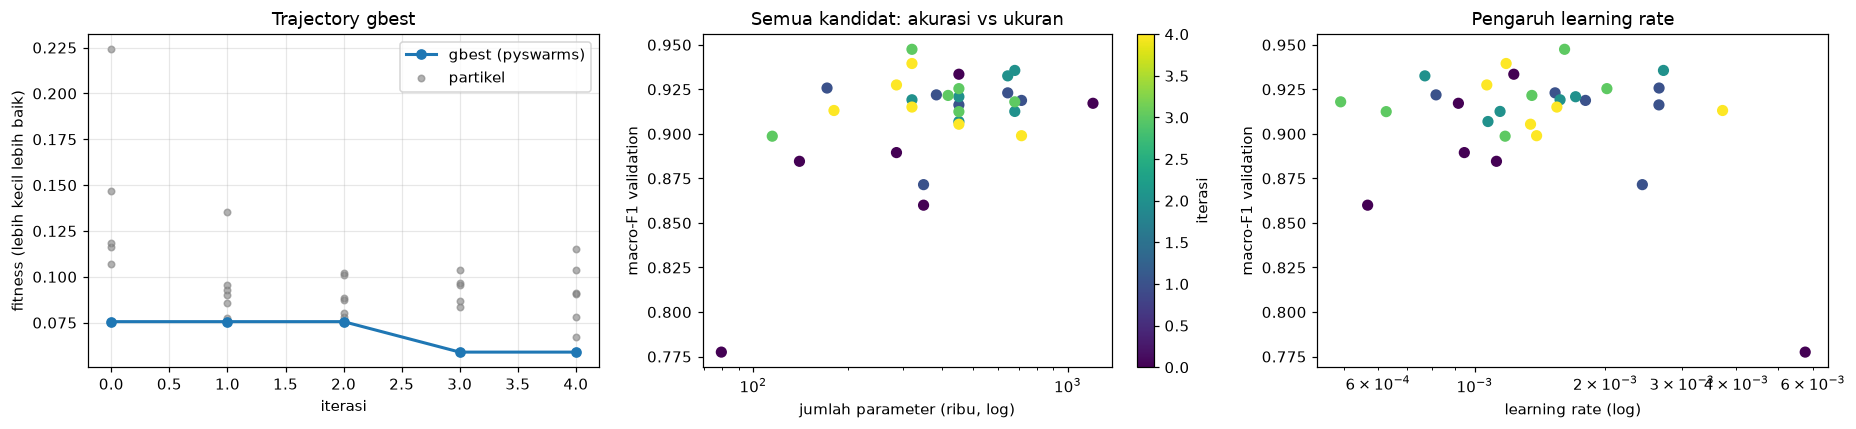

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4))
axes[0].plot(range(len(pso.cost_history)), pso.cost_history, "o-", lw=2, label="gbest (pyswarms)")
for it, g in log_df.groupby("iterasi"):
    axes[0].scatter([it] * len(g), g["fitness"], c="gray", s=18, alpha=.6, label="partikel" if it == 0 else None)
axes[0].set_xlabel("iterasi"); axes[0].set_ylabel("fitness (lebih kecil lebih baik)"); axes[0].set_title("Trajectory gbest")
axes[0].legend(); axes[0].grid(alpha=.3)
sc = axes[1].scatter(log_df["params"] / 1e3, log_df["f1_val"], c=log_df["iterasi"], cmap="viridis", s=40)
axes[1].set_xscale("log"); axes[1].set_xlabel("jumlah parameter (ribu, log)"); axes[1].set_ylabel("macro-F1 validation")
axes[1].set_title("Semua kandidat: akurasi vs ukuran"); plt.colorbar(sc, ax=axes[1], label="iterasi")
axes[2].scatter(log_df["lr"], log_df["f1_val"], c=log_df["iterasi"], cmap="viridis", s=40)
axes[2].set_xscale("log"); axes[2].set_xlabel("learning rate (log)"); axes[2].set_ylabel("macro-F1 validation")
axes[2].set_title("Pengaruh learning rate"); plt.tight_layout(); plt.show()

**Hasil Jawaban 23c.**
- **Konfigurasi terbaik PSO:** **F = 128 filter, kernel K = 11, dropout 0.017, dense 32 unit, learning rate ≈ 1.6×10⁻³**, dengan **320.230 parameter**.
  - Hasilnya: **macro-F1 validation 0.9475**, fitness **0.0589** = (1 − 0.9475) + 0.02 × 0.32.
  - Kernel 11 sampel ≈ 0.22 detik, cukup panjang untuk menangkap satu "hentakan" langkah kaki.
- ***Trajectory* gbest:**
  - Iterasi 0 (posisi acak): fitness partikel tersebar 0.076–0.224. Yang terburuk adalah lr terbesar (5.8×10⁻³) dengan dropout 0.48 (macro-F1 hanya 0.78).
  - gbest bertahan di 0.0756 selama iterasi 0–2, lalu turun ke **0.0589 di iterasi 3**.
  - Sebaran fitness partikel menyempit dari iterasi ke iterasi (iterasi 0: 0.08–0.22, iterasi 4: 0.07–0.12). Kawanan bergerak ke daerah yang menjanjikan.
- **Kawanan cepat konvergen ke "filter 128, kernel besar".** Sejak iterasi 1 hampir semua partikel memilih F = 128; kernel baru mengumpul ke 9–11 mulai iterasi 2–3. Dari plot tengah, model **lebih besar tidak otomatis lebih baik**: kandidat 1.2 juta parameter (dense 256) hanya mencapai macro-F1 0.917 dan kena penalti terbesar. Penalti parameter berhasil mendorong dense ke 32.
- **Catatan kritis: evaluasi fitness berisik.**
  - Arsitektur yang hampir sama (F = 128, K = 11, dense 32, dropout ≈ 0–0.11, lr ≈ 1.2–1.6×10⁻³) mendapat macro-F1 val **0.915, 0.919, 0.940, dan 0.948** di evaluasi berbeda. Contoh paling jelas: kandidat nomor 15 (dropout 0.014, lr 0.0016) dan nomor 20 (dropout 0.017, lr 0.0016) praktis identik dan dilatih dengan seed yang sama, tetapi macro-F1 val-nya **0.919 vs 0.948**. Selisih hingga 0.03 muncul hanya dari perbedaan sangat kecil dropout/lr dan pelatihan yang hanya maksimal 8 epoch.
  - Sebagian keunggulan gbest kemungkinan **faktor beruntung** (*winner's curse*). Buktinya, saat dilatih ulang dengan 3 seed, macro-F1 val rata-ratanya 0.943, sedikit di bawah 0.9475 saat pencarian.
- **Biaya:** 30 kandidat unik (tidak ada yang kembar, jadi cache tidak terpakai) dalam **43.2 menit**. Kandidat F = 128, K = 11 adalah yang paling lambat (80–180 detik per kandidat di CPU).

## 5. Evaluation

### Jawaban 23d — CNN hasil PSO vs baseline manual di test set

**Baseline manual** dipilih seperti kebiasaan umum tanpa tuning: F = 32, K = 5, dropout 0.3, dense 64, lr = 0.001.

**Protokol yang adil untuk kedua model:**
- Dilatih ulang dengan anggaran lebih longgar (maksimal 30 epoch, *patience* 5) pada data latih yang sama.
- Validation tetap dipakai **hanya untuk early stopping**.
- Diulang dengan **3 seed** (47, 48, 49) supaya perbedaan tidak sekadar keberuntungan inisialisasi.
- Test set dievaluasi **sekali per model per seed**, tanpa memilih apa pun berdasarkan test.

In [13]:
BASE_CFG = {"filters": 32, "kernel": 5, "dropout": 0.3, "dense": 64, "lr": 1e-3}
final_rows, final_models = [], {}
for nama, cfg in [("Baseline manual", BASE_CFG), ("PSO terbaik", BEST_CFG)]:
    for s in [SEED, SEED + 1, SEED + 2]:
        t0 = time.time()
        m, f1v, h = train_cnn(cfg, Xt_tr, yt_tr, Xt_va, yt_va, seed=s, max_epochs=30, patience=5)
        dt = time.time() - t0
        p = predict(m, Xt_te)
        final_models[(nama, s)] = (m, p)
        final_rows.append({"model": nama, "seed": s, "params": count_params(m), "epoch_dilatih": len(h),
                           "waktu_latih_s": dt, "macroF1_val": f1v, "accuracy_test": accuracy_score(y_test, p),
                           "macroF1_test": f1_score(y_test, p, average="macro")})
        print(f"{nama:16s} seed {s}: acc test={final_rows[-1]['accuracy_test']:.4f}, "
              f"macro-F1 test={final_rows[-1]['macroF1_test']:.4f}, {dt:.0f} s")
final = pd.DataFrame(final_rows)
display(final.round(4))
final.groupby("model")[["params", "waktu_latih_s", "macroF1_val", "accuracy_test", "macroF1_test"]].agg(["mean", "std"]).round(4)

Baseline manual  seed 47: acc test=0.9074, macro-F1 test=0.9087, 57 s


Baseline manual  seed 48: acc test=0.9220, macro-F1 test=0.9240, 50 s


Baseline manual  seed 49: acc test=0.8931, macro-F1 test=0.8943, 38 s


PSO terbaik      seed 47: acc test=0.9301, macro-F1 test=0.9314, 183 s


PSO terbaik      seed 48: acc test=0.9203, macro-F1 test=0.9218, 150 s


PSO terbaik      seed 49: acc test=0.9274, macro-F1 test=0.9293, 211 s


,model,seed,params,epoch_dilatih,waktu_latih_s,macroF1_val,accuracy_test,macroF1_test
0,Baseline manual,47,72134,30,57.4154,0.9393,0.9074,0.9087
1,Baseline manual,48,72134,26,50.0944,0.9295,0.9220,0.9240
2,Baseline manual,49,72134,20,38.0480,0.9206,0.8931,0.8943
3,PSO terbaik,47,320230,13,182.9421,0.9475,0.9301,0.9314
4,PSO terbaik,48,320230,11,150.2362,0.9323,0.9203,0.9218
5,PSO terbaik,49,320230,15,210.6920,0.9480,0.9274,0.9293


params      waktu_latih_s          macroF1_val         accuracy_test         macroF1_test        
                     mean  std          mean      std        mean     std          mean     std         mean     std
model                                                                                                               
Baseline manual   72134.0  0.0       48.5193   9.7793      0.9298  0.0093        0.9075  0.0144       0.9090  0.0148
PSO terbaik      320230.0  0.0      181.2901  30.2617      0.9426  0.0089        0.9259  0.0051       0.9275  0.0051

=== CNN hasil PSO (seed 47) ===
                    precision    recall  f1-score   support

           WALKING      0.994     0.935     0.964       496
  WALKING_UPSTAIRS      0.947     0.996     0.971       471
WALKING_DOWNSTAIRS      0.941     0.955     0.948       420
           SITTING      0.904     0.882     0.893       491
          STANDING      0.886     0.934     0.909       532
            LAYING      0.919     0.888     0.903       537

          accuracy                          0.930      2947
         macro avg      0.932     0.932     0.931      2947
      weighted avg      0.931     0.930     0.930      2947



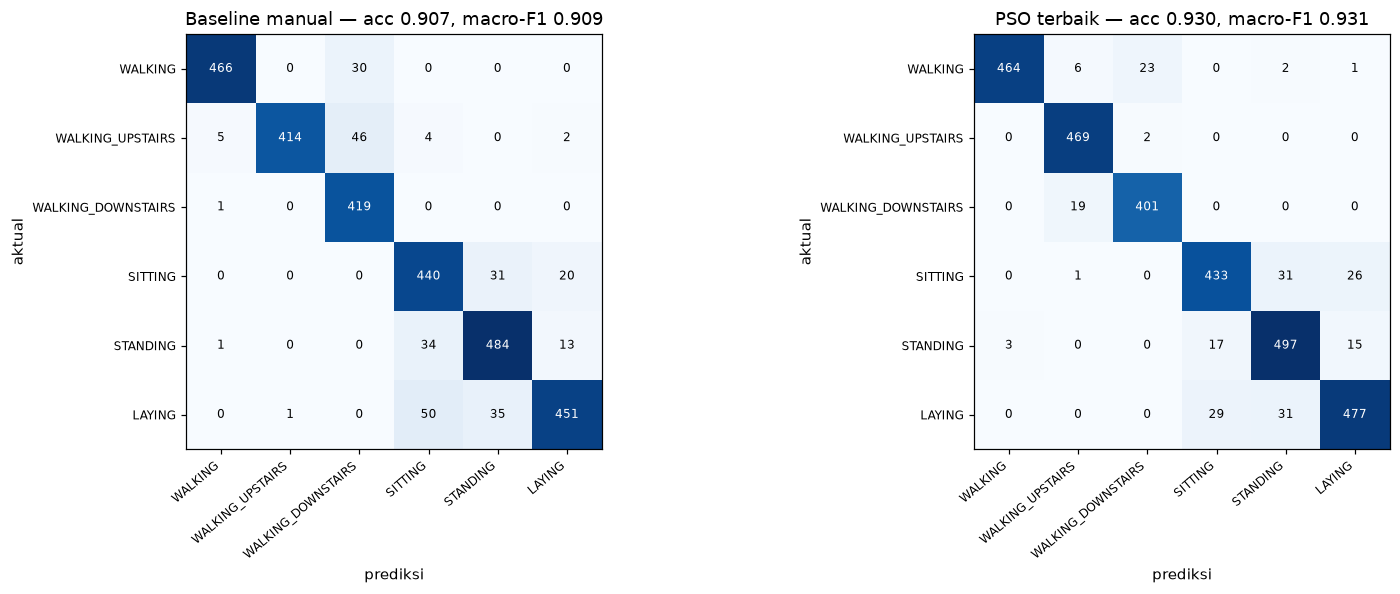

In [14]:
m_best, p_best = final_models[("PSO terbaik", SEED)]
m_base, p_base = final_models[("Baseline manual", SEED)]
print("=== CNN hasil PSO (seed 47) ===")
print(classification_report(y_test, p_best, target_names=ACT_NAMES, digits=3))
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
for ax, p, judul in [(axes[0], p_base, "Baseline manual"), (axes[1], p_best, "PSO terbaik")]:
    cm = confusion_matrix(y_test, p)
    ax.imshow(cm, cmap="Blues")
    for i in range(6):
        for j in range(6):
            ax.text(j, i, cm[i, j], ha="center", va="center", color="white" if cm[i, j] > cm.max() / 2 else "black", fontsize=8)
    ax.set_xticks(range(6)); ax.set_xticklabels(ACT_NAMES, rotation=40, ha="right", fontsize=8)
    ax.set_yticks(range(6)); ax.set_yticklabels(ACT_NAMES, fontsize=8)
    ax.set_xlabel("prediksi"); ax.set_ylabel("aktual")
    ax.set_title(f"{judul} — acc {accuracy_score(y_test, p):.3f}, macro-F1 {f1_score(y_test, p, average='macro'):.3f}")
plt.tight_layout(); plt.show()

In [15]:
cm = confusion_matrix(y_test, p_best)
off = [(cm[i, j], ACT_NAMES[i], ACT_NAMES[j]) for i in range(6) for j in range(6) if i != j]
print("Pasangan yang paling sering tertukar (aktual → prediksi), model PSO seed 47:")
for n, a, b in sorted(off, reverse=True)[:4]:
    print(f"  {a:20s} → {b:20s}: {n} window")

Pasangan yang paling sering tertukar (aktual → prediksi), model PSO seed 47:
  SITTING              → STANDING            : 31 window
  LAYING               → STANDING            : 31 window
  LAYING               → SITTING             : 29 window
  SITTING              → LAYING              : 26 window


In [16]:
ringkas = final.groupby("model").agg(f1_test=("macroF1_test", "mean"), waktu=("waktu_latih_s", "mean"), params=("params", "mean"))
gain = ringkas.loc["PSO terbaik", "f1_test"] - ringkas.loc["Baseline manual", "f1_test"]
biaya_tuning = sum(c["detik"] for c in cache.values())
print(f"Selisih macro-F1 test rata-rata (PSO − baseline): {gain:+.4f}")
print(f"Biaya tuning PSO: {len(cache)} pelatihan kandidat, {biaya_tuning/60:.1f} menit "
      f"(≈ {biaya_tuning / ringkas.loc['Baseline manual', 'waktu']:.1f}× waktu melatih satu baseline penuh)")
print(f"Ukuran model: PSO {ringkas.loc['PSO terbaik','params']:,.0f} vs baseline {ringkas.loc['Baseline manual','params']:,.0f} parameter")

Selisih macro-F1 test rata-rata (PSO − baseline): +0.0185
Biaya tuning PSO: 30 pelatihan kandidat, 43.2 menit (≈ 53.4× waktu melatih satu baseline penuh)
Ukuran model: PSO 320,230 vs baseline 72,134 parameter


**Hasil Jawaban 23d** (rata-rata ± std dari 3 seed):

| Model | Parameter | Waktu latih | macro-F1 val | Accuracy test | **macro-F1 test** |
|---|---|---|---|---|---|
| Baseline manual (32, 5, 0.3, 64, 1e-3) | 72.134 | 49 ± 10 s | 0.930 | 0.908 ± 0.014 | **0.909 ± 0.015** |
| PSO terbaik (128, 11, 0.017, 32, 1.6e-3) | 320.230 | 181 ± 30 s | 0.943 | 0.926 ± 0.005 | **0.928 ± 0.005** |

**Performa.**
- CNN hasil PSO **lebih baik +1.85 poin macro-F1** di test. Ketiga seed PSO (0.922–0.931) berada di atas rata-rata baseline, dan variasinya **3× lebih kecil** (std 0.005 vs 0.015). Baseline sempat turun sampai 0.894 di seed 49, jadi konfigurasi PSO juga **lebih stabil**.
- Dari confusion matrix, **perbaikan terbesar ada di aktivitas berjalan**:
  - Baseline salah mengira **46 window WALKING_UPSTAIRS sebagai DOWNSTAIRS** dan 30 WALKING sebagai DOWNSTAIRS. Pada model PSO, angkanya turun menjadi 2 dan 23.
  - Kernel lebih panjang (11 vs 5) dan filter lebih banyak (128 vs 32) mampu menangkap ritme langkah naik dan turun tangga yang hanya beda tipis.
- **Yang tidak membaik: aktivitas statis.** Pasangan paling sering tertukar pada model PSO adalah **SITTING → STANDING (31)**, **LAYING → STANDING (31)**, **LAYING → SITTING (29)**, dan **SITTING → LAYING (26)**.
  - Penyebabnya ada di data, bukan di hyperparameter. Input yang dipakai adalah *body_acc*, yang komponen gravitasinya sudah dibuang. Padahal yang membedakan duduk, berdiri, dan berbaring adalah **orientasi HP terhadap gravitasi**.
  - Tuning hyperparameter tidak bisa menciptakan informasi yang tidak ada di input. Menambah 3 channel *total_acc* (berisi gravitasi) kemungkinan memberi dampak jauh lebih besar daripada tuning.

**Apakah peningkatan sebanding dengan biaya tuning?**

| Biaya | Baseline | PSO |
|---|---|---|
| Tuning | 0 | 43.2 menit (30 pelatihan, ≈ 53× melatih satu baseline) |
| Ukuran model | 72 ribu param | 320 ribu param (4.4×) |
| Waktu latih final | 49 s | 181 s (3.7×) |
| Keuntungan | – | +1.85 poin macro-F1, variasi antar-seed 3× lebih kecil |

- **Untuk riset atau prototipe sekali jalan:** layak. 43 menit di laptop masih murah. Hasilnya lebih akurat, lebih stabil, dan PSO sekaligus memberi wawasan: kernel panjang membantu, dense besar tidak perlu, dan lr di kisaran 1–3×10⁻³ paling aman.
- **Untuk aplikasi HP:** perlu ditimbang. Model 4.4× lebih besar untuk tambahan < 2 poin F1. Kalau perangkatnya terbatas, λ penalti perlu dinaikkan agar PSO memilih model yang lebih ramping.
- **Secara metodologi:** dengan hanya 30 evaluasi berisik (1 seed, ≤ 8 epoch), PSO belum tentu menemukan optimum sebenarnya. Kandidat dengan F = 64 (seperti indeks 9 atau 27, sekitar 170–180 ribu parameter, macro-F1 val ≈ 0.91–0.93) mungkin hampir setara dengan biaya separuhnya. Peningkatan yang lebih besar kemungkinan datang dari **memperbaiki input** (menambah *total_acc*) daripada menambah anggaran tuning.

## 6. Interpretasi Hasil

### 6.1 Prediksi vs aktual pada 20 window test (subjek yang tidak pernah dilihat)

In [17]:
rng = np.random.default_rng(SEED)
pilih = np.sort(rng.choice(len(y_test), 20, replace=False))
tab = pd.DataFrame({"index_window": pilih, "subjek": s_test[pilih], "aktual": [ACT_NAMES[i] for i in y_test[pilih]],
                    "prediksi_PSO": [ACT_NAMES[i] for i in p_best[pilih]],
                    "prediksi_baseline": [ACT_NAMES[i] for i in p_base[pilih]]})
tab["PSO benar?"] = tab["aktual"] == tab["prediksi_PSO"]
tab

,index_window,subjek,aktual,prediksi_PSO,prediksi_baseline,PSO benar?
0,230,2,WALKING,WALKING,WALKING,True
1,285,2,WALKING_UPSTAIRS,WALKING_UPSTAIRS,WALKING_UPSTAIRS,True
2,304,4,STANDING,STANDING,SITTING,True
3,335,4,SITTING,SITTING,SITTING,True
4,397,4,WALKING,WALKING,WALKING,True
5,528,4,LAYING,LAYING,LAYING,True
6,589,4,WALKING_DOWNSTAIRS,WALKING_DOWNSTAIRS,WALKING_DOWNSTAIRS,True
7,942,10,SITTING,SITTING,SITTING,True
8,1051,10,WALKING_UPSTAIRS,WALKING_UPSTAIRS,WALKING_UPSTAIRS,True
9,1258,12,LAYING,LAYING,LAYING,True


**Interpretasi uji akhir.**
- Pada 20 window acak dari 9 subjek test (orang yang tidak pernah dilihat model), CNN hasil PSO **menebak benar ke-20-nya**.
- Baseline salah 1: window 304 (subjek 4) yang aktualnya STANDING ditebak SITTING. Ini persis tipe kesalahan statis yang dibahas di 23d.
- Secara keseluruhan test set, model PSO salah di sekitar 7% window, dan sebagian besar kesalahannya ada di antara tiga postur statis.

### 6.2 Pengecekan kriteria kesuksesan

| Kriteria | Target | Hasil | Status |
|---|---|---|---|
| Accuracy dan macro-F1 test CNN PSO | ≥ 0.88 | 0.926 / 0.928 (rata-rata 3 seed) | ✅ |
| PSO ≥ baseline | macro-F1 test rata-rata | 0.928 vs 0.909 | ✅ |
| Anggaran ≤ 30 evaluasi | ≤ 30 | 30 | ✅ |
| Anggaran waktu ≤ 25 menit | ≤ 25 menit | **43.2 menit** | ❌ (kandidat filter 128 + kernel 11 jauh lebih lambat dari perkiraan di CPU) |

### 6.3 Kesimpulan
1. Hyperparameter campuran diskret/kontinu bisa dioptimasi PSO dengan **menormalisasi semua dimensi ke [0, 1]** lalu memetakannya ke "laci" pilihan valid. Learning rate dicari di skala log, dan *velocity clamp* 0.25 menjaga partikel tidak melompat terlalu jauh.
2. Fitness 1 − macro-F1 val + 0.02 × (parameter/10⁶) menyeimbangkan akurasi per kelas dan ukuran model. Penalti ini terbukti menyingkirkan kandidat 1.2 juta parameter.
3. Konfigurasi terbaik (**F = 128, K = 11, dropout ≈ 0, dense 32, lr ≈ 1.6×10⁻³**) mencapai **macro-F1 test 0.928 ± 0.005**, lebih tinggi dan lebih stabil dari baseline manual (0.909 ± 0.015). Keuntungan terbesar ada pada membedakan naik dan turun tangga.
4. Biayanya: 43 menit tuning (melebihi target 25 menit), model 4.4× lebih besar, dan latih 3.7× lebih lama. Sepadan untuk akurasi riset, tetapi perlu ditimbang untuk perangkat terbatas.
5. Keterbatasan dan pengembangan:
   - Fitness berisik karena hanya 1 seed dan ≤ 8 epoch, sehingga gbest sebagian dipengaruhi keberuntungan. Bisa diatasi dengan rata-rata 2 seed per kandidat atau melanjutkan iterasi.
   - Kesalahan dominan di postur statis tidak bisa diperbaiki dengan tuning. Perlu menambah channel *total_acc* agar informasi orientasi terhadap gravitasi tersedia.